# Tuning the initial learning rate for gesture detection

**Question.** How does the initial learning rate (`lr0`) affect YOLOv8s as it learns palm, fist, thumbs-up and thumbs-down? The learning rate scales each training update. Smaller updates may preserve useful pretrained features but take longer to adapt. Larger updates may learn faster or produce a less stable validation curve. The three runs below test those possibilities within the same 50-epoch budget.

| Run | Initial learning rate | Relative to baseline |
|---|---:|---:|
| Lower | 0.0025 | ¼× |
| Lower | 0.005 | ½× |
| Group baseline, already trained | 0.01 | 1× |
| Higher | 0.02 | 2× |

Each new run starts from the same COCO-pretrained `yolov8s.pt` and changes only `lr0` in the group's `BASELINE`. Validation selects each run's checkpoint. The four checkpoints are then compared on the same **128 team photos**. Use team mAP50 as the headline measure for this experiment, and check whether F1 and fist detection at the booth's operating threshold tell the same story.

## 1. Open the group project

**If the group's project and dataset already work on this computer**, put this notebook beside `gesture_eval.py`, open it in JupyterLab with the **Python (CV Group 6)** kernel, and run the two setup cells below. They check the files and show the experiment plan before training begins.

**First-time setup on a Mac**

1. In Google Drive, find the shared folder **ComputerVisionProject-Group6-Dataset**. Choose **Organize → Add shortcut → My Drive** and check that you can open its `images` and `labels` folders in Finder through Google Drive for desktop.
2. In Terminal, get the group's code from the `Ben` branch and create a branch for your experiment. Use your existing project checkout and personal branch if you have them.

```bash
git clone --branch Ben https://github.com/Amynguyen2424/Computer-Vision-Project-Group6.git
cd Computer-Vision-Project-Group6
git switch -c amy-lr0
```

3. Copy this notebook into that project folder. From the same Terminal window, set up the group's Python environment and build the prepared dataset.

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install torch torchvision
python -m pip install -r requirements.txt
python -m ipykernel install --user --name cv-group6 --display-name "Python (CV Group 6)"
python prepare_dataset.py
jupyter lab
```

The preparation script builds the group's fixed split and applies its gesture-label corrections. Its final counts should be **1,280 train, 160 validation, 160 test**, with **128 team photos inside test**. If your shared data is already downloaded elsewhere, run `python prepare_dataset.py --images "/path/to/images" --labels "/path/to/labels"` with your actual folders. Training all three rates on a laptop CPU can take hours. The same notebook runs on the group's configured GPU machine.

[Group project and setup guide](https://github.com/Amynguyen2424/Computer-Vision-Project-Group6/tree/Ben)

In [1]:
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "gesture_eval.py").is_file():
    raise FileNotFoundError(
        "Open this notebook from the Group 6 project folder, beside gesture_eval.py. "
        "The first-time setup above explains how to get that folder."
    )

required_files = [
    "data.yaml", "data_team_test.yaml", "models/baseline_best.pt",
    "dataset/split_manifest.csv", "dataset/test_team.txt",
]
missing = [name for name in required_files if not (ROOT / name).is_file()]
if missing:
    raise FileNotFoundError(
        "Missing project files: " + ", ".join(missing) + ". "
        "Get the Ben branch for the model and YAML files. "
        "Run python prepare_dataset.py for the dataset files."
    )

import shutil
from tempfile import TemporaryDirectory

import matplotlib.pyplot as plt
import pandas as pd
import torch
import ultralytics
import yaml
from IPython.display import display
from ultralytics import YOLO

from gesture_eval import BASELINE, error_analysis, evaluate

RATES = (0.0025, 0.005, 0.02)
BASE_RATE = BASELINE["lr0"]
if BASE_RATE != 0.01 or BASELINE["optimizer"] != "SGD":
    raise ValueError("Check the group baseline. This experiment uses SGD with lr0=0.01.")
if len(set(RATES)) != 3 or BASE_RATE in RATES or min(RATES) <= 0:
    raise ValueError("Choose three distinct positive learning rates different from the baseline.")

MODELS = ROOT / "models"
RESULTS = ROOT / "results"
RUNS = {"baseline": BASE_RATE, **{f"lr0_{rate:g}": rate for rate in RATES}}
print(f"Ultralytics {ultralytics.__version__} | PyTorch {torch.__version__}")
if torch.cuda.is_available():
    TRAIN_DEVICE = 0
    device_label = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    TRAIN_DEVICE = "mps"
    device_label = "Apple GPU (Metal)"
else:
    TRAIN_DEVICE = "cpu"
    device_label = "CPU"
print(f"Training hardware: {device_label}")
print(f"SGD | image size {BASELINE['imgsz']} | batch {BASELINE['batch']} | "
      f"up to {BASELINE['epochs']} epochs | patience {BASELINE['patience']} | seed {BASELINE['seed']}")
display(pd.Series(RUNS, name="Initial learning rate").sort_values().to_frame())

Ultralytics 8.4.202 | PyTorch 2.11.0+cu128
Training hardware: NVIDIA GeForce RTX 5060 Ti
SGD | image size 640 | batch 16 | up to 50 epochs | patience 15 | seed 0


,Initial learning rate
lr0_0.0025,0.0025
lr0_0.005,0.0050
baseline,0.0100
lr0_0.02,0.0200


In [2]:
dataset = ROOT / "dataset"
manifest = pd.read_csv(dataset / "split_manifest.csv")
counts = manifest["split"].value_counts().to_dict()
team = manifest.loc[manifest["source"] == "team"]
team_list = (dataset / "test_team.txt").read_text().splitlines()
listed_names = sorted(Path(line.strip()).name for line in team_list if line.strip())

if counts != {"train": 1280, "val": 160, "test": 160}:
    raise ValueError(f"Found {counts}. Rebuild the project split with python prepare_dataset.py.")
if len(team) != 128 or not team["split"].eq("test").all() or listed_names != sorted(team["file"]):
    raise ValueError("The team test list must match the 128 team photos in the test split.")

for split, group in manifest.groupby("split"):
    expected = set(group["file"])
    image_files = {p.name for p in (dataset / "images" / split).iterdir()
                   if p.suffix.lower() in {".jpg", ".jpeg", ".png"}}
    label_files = {p.name for p in (dataset / "labels" / split).glob("*.txt")}
    if image_files != expected or label_files != {Path(name).stem + ".txt" for name in expected}:
        raise ValueError(f"Image or label files in {split} differ from the manifest. Rebuild the dataset.")

display(pd.crosstab(manifest["split"], manifest["source"], margins=True))
print(f"Ready. Each model will be evaluated on the same {len(team)} team photos.")

source,hagrid,team,All
split,,,
test,32,128,160
train,1280,0,1280
val,160,0,160
All,1472,128,1600


Ready. Each model will be evaluated on the same 128 team photos.


## 2. Train the three learning rates

Run the next cell once. It makes a fresh copy of the baseline settings for each value and loads the original pretrained weights each time. SGD, image size, batch size, augmentations, seed and early stopping all carry over from the group baseline. Early stopping can produce different run lengths even though every run has the same budget.

For each completed run the cell saves its validation-selected `best.pt`, settings and training history. If the session disconnects, run the notebook again. Completed rates are reused, and an unfinished rate starts again. The existing group baseline only needs to be scored.

The notebook uses an available NVIDIA or Apple GPU for training and records the device in each run’s saved settings. The group evaluator scores all four checkpoints on the same machine.

In [3]:
def train_rate(rate):
    name = f"lr0_{rate:g}"
    settings = {**BASELINE, "lr0": rate}
    weights = MODELS / f"{name}_best.pt"
    out = RESULTS / name
    saved_args = out / "args.yaml"
    history = out / "results.csv"

    if weights.is_file() and saved_args.is_file() and history.is_file():
        prior = yaml.safe_load(saved_args.read_text())
        # Ultralytics can adjust worker count for the available hardware.
        differences = [key for key, value in settings.items()
                       if key != "workers" and prior.get(key) != value]
        if differences:
            raise ValueError(f"{name} has different saved settings: {differences}. "
                             "Move the old run's weights and results aside before rerunning.")
        print(f"Reusing {weights.name}")
        return

    print(f"Training {name} from yolov8s.pt")
    model = YOLO("yolov8s.pt")
    model.train(**settings, device=TRAIN_DEVICE, project=str(ROOT / "runs"), name=name, exist_ok=False)
    run = Path(model.trainer.save_dir)
    out.mkdir(parents=True, exist_ok=True)
    for filename in ("args.yaml", "results.csv"):
        shutil.copy2(run / filename, out / filename)
    if (run / "results.png").is_file():
        shutil.copy2(run / "results.png", out / "results.png")

    # Publish the checkpoint only after its training history has been saved.
    with TemporaryDirectory(dir=MODELS) as stage:
        staged = Path(stage) / weights.name
        shutil.copy2(run / "weights" / "best.pt", staged)
        staged.replace(weights)
    print(f"Saved {weights.relative_to(ROOT)}")

for rate in RATES:
    train_rate(rate)

Reusing lr0_0.0025_best.pt
Reusing lr0_0.005_best.pt
Reusing lr0_0.02_best.pt


## 3. Score the baseline and three new checkpoints

The group's `evaluate()` reports validation, full-test and team-only metrics. Its `error_analysis()` checks what the booth would actually do at confidence **0.25** and a box-overlap threshold (IoU) of **0.50**. Every model is evaluated at the baseline image size of **640**.

- **Team mAP50** measures detection across confidence thresholds. A gesture must have the correct class and its predicted box must overlap the labeled box by at least 0.50 IoU. **Team mAP50–95** also tests stricter box alignment.
- **F1 at 0.25** balances false gestures and missed hands at the booth's fixed confidence setting. The separate **team F1** column comes from the group's standard YOLO evaluator.
- **Fists found at 0.25** counts labeled fists correctly recognized at that same operating point. A missed or misclassified fist means the stop-countdown gesture failed.

The group previously recorded **0.8448 team mAP50** and **0.8212 F1 at confidence 0.25** for the baseline. Use the baseline row computed below on your copy of the data for all differences. Keep the three rates fixed for this comparison. The team-photo scores describe performance on the photos used to compare the models. [Saved baseline scores](https://github.com/Amynguyen2424/Computer-Vision-Project-Group6/blob/Ben/results/baseline/metrics.json) · [Saved operating-threshold scores](https://github.com/Amynguyen2424/Computer-Vision-Project-Group6/blob/Ben/results/baseline/error_analysis.json)

In [4]:
rows = []
for name, rate in RUNS.items():
    weights = MODELS / f"{name}_best.pt"
    # Keep the baseline re-score in this experiment's own output folder.
    out = RESULTS / ("lr0_baseline_eval" if name == "baseline" else name)
    overall, per_class = evaluate(weights, BASELINE["imgsz"], out)
    errors = error_analysis(weights, BASELINE["imgsz"], out, conf=0.25, iou_thr=0.5)

    validation = overall.loc[f"validation ({counts['val']})"]
    team_score = overall.loc[f"test, team only ({len(team)})"]
    fists = errors["hands"].loc[errors["hands"]["class"] == "fist"]
    rows.append({
        "run": name, "lr0": rate,
        "val mAP50-95": validation["mAP50-95"],
        "team mAP50": team_score["mAP50"], "team mAP50-95": team_score["mAP50-95"],
        "team precision": team_score["precision"], "team recall": team_score["recall"],
        "team F1": team_score["F1"], "F1 @ 0.25": errors["summary"]["F1"],
        "fist mAP50": per_class.loc[("test (team only)", "fist"), "mAP50"],
        "fists found @ 0.25": int(fists["correct"].sum()), "fists labeled": len(fists),
    })

summary = pd.DataFrame(rows).set_index("run").sort_values("lr0")
for metric in ["team mAP50", "F1 @ 0.25"]:
    summary[f"{metric} change (pp)"] = 100 * (summary[metric] - summary.loc["baseline", metric])

summary_path = RESULTS / "tuning_lr0_summary.csv"
summary.to_csv(summary_path, float_format="%.6f")
display(summary.round(3))
print(f"Saved {summary_path.relative_to(ROOT)}. Changes are in percentage points (pp).")

Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 2752.8±482.1 MB/s, size: 1231.7 KB)
val: Scanning C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\dataset\labels\val.cache... 160 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160 47.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 3.5it/s 2.8s.2ss
                   all        160        160       0.99      0.984       0.99      0.748
Speed: 0.7ms preprocess, 3.1ms inference, 0.0ms loss, 0.7ms postprocess per image
Results saved to C:\Users\benka\WebstormProjects\Computer-Vision-Project-Group6\runs\lr0_baseline_eval_val
Ultralytics 8.4.202  Python-3.14.7 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5060 Ti, 16283MiB)
Model summary (fused): 72 layers, 11,127

,lr0,val mAP50-95,team mAP50,team mAP50-95,team precision,team recall,team F1,F1 @ 0.25,fist mAP50,fists found @ 0.25,fists labeled,team mAP50 change (pp),F1 @ 0.25 change (pp)
run,,,,,,,,,,,,,
lr0_0.0025,0.002,0.757,0.856,0.449,0.855,0.770,0.810,0.774,0.647,25,36,1.156,-4.68
lr0_0.005,0.005,0.756,0.857,0.425,0.873,0.815,0.843,0.828,0.669,24,36,1.265,0.68
baseline,0.010,0.748,0.845,0.419,0.894,0.775,0.830,0.821,0.625,23,36,0.000,0.00
lr0_0.02,0.020,0.741,0.821,0.400,0.840,0.769,0.803,0.780,0.545,20,36,-2.387,-4.12


Saved results\tuning_lr0_summary.csv. Changes are in percentage points (pp).


## 4. Read the comparison

The left plot shows how quickly each rate learns on validation data. Curves can end at different epochs because early stopping is enabled. The right plot shows each variant's difference from the baseline on the team photos. A value of **+2** means two percentage points higher than the baseline. A negative value means the baseline scored higher.

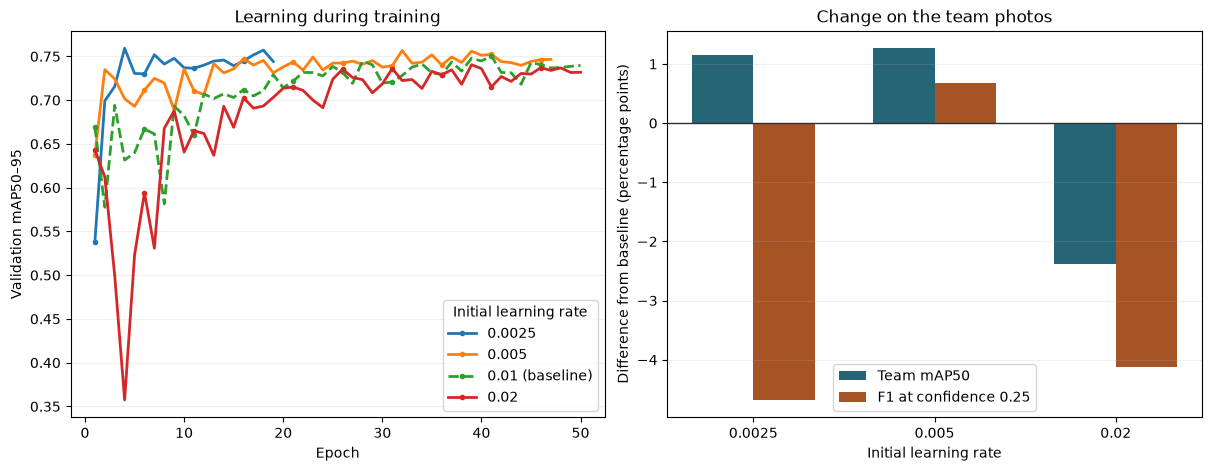

Saved results\tuning_lr0_comparison.png


In [5]:
fig, (curve_ax, team_ax) = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True)

for name, row in summary.iterrows():
    history_path = RESULTS / name / "results.csv"
    if name == "baseline" and not history_path.is_file():
        print("Baseline training history is unavailable. Its re-scored test metrics are in the table.")
        continue
    history = pd.read_csv(history_path)
    history.columns = history.columns.str.strip()
    baseline = name == "baseline"
    label = f"{row['lr0']:g}" + (" (baseline)" if baseline else "")
    curve_ax.plot(history["epoch"], history["metrics/mAP50-95(B)"], label=label,
                 linestyle="--" if baseline else "-", linewidth=2,
                 marker="o", markersize=3, markevery=5)
curve_ax.set(title="Learning during training", xlabel="Epoch", ylabel="Validation mAP50–95")
curve_ax.legend(title="Initial learning rate")
curve_ax.grid(axis="y", alpha=0.2)

variants = summary.drop(index="baseline")
positions = list(range(len(variants)))
width = 0.34
team_ax.bar([x - width / 2 for x in positions], variants["team mAP50 change (pp)"],
            width=width, color="#256576", label="Team mAP50")
team_ax.bar([x + width / 2 for x in positions], variants["F1 @ 0.25 change (pp)"],
            width=width, color="#a65326", label="F1 at confidence 0.25")
team_ax.axhline(0, color="#303030", linewidth=1)
team_ax.set_xticks(positions, [f"{rate:g}" for rate in variants["lr0"]])
team_ax.set(title="Change on the team photos", xlabel="Initial learning rate",
            ylabel="Difference from baseline (percentage points)")
team_ax.legend()
team_ax.grid(axis="y", alpha=0.2)

plot_path = RESULTS / "tuning_lr0_comparison.png"
fig.savefig(plot_path, dpi=160)
plt.show()
print(f"Saved {plot_path.relative_to(ROOT)}")

## 5. Results on the team photos

**Choose `lr0=0.005` for the learning-rate comparison.** It achieved the highest team mAP50, **0.8661**, a gain of **2.19 percentage points** over the group's `0.01` baseline. It also had the highest F1 at the photo booth's confidence threshold of 0.25, **0.8291**.

| Initial learning rate | Selected epoch / epochs run | Team mAP50 | Team mAP50–95 | F1 at 0.25 | Fists recognized at 0.25 |
|---|---:|---:|---:|---:|---:|
| 0.01 (group baseline) | 41 / 50 | 0.8442 | 0.4155 | 0.8224 | 23 / 36 |
| 0.0025 | 4 / 19 | 0.8592 | **0.4465** | 0.7781 | **25 / 36** |
| **0.005** | **32 / 47** | **0.8661** | 0.4240 | **0.8291** | 24 / 36 |
| 0.02 | 39 / 50 | 0.8201 | 0.3972 | 0.7815 | 20 / 36 |

At confidence 0.25, `0.005` correctly recognized **131 of 155 hands**, compared with **125** for the baseline. It recognized 10 hands the baseline missed or misclassified and lost 4 the baseline had recognized. This included a net gain of one correctly recognized stop-countdown fist. The smallest rate, `0.0025`, caught one additional fist compared with `0.005`, but it also produced **39 detections on background**, compared with **26** for `0.005`. That helps explain its lower operating F1.

The training curves show how the size of the updates affected learning early on. By epoch 5, validation mAP50–95 was **0.7305** at `0.0025`, **0.6929** at `0.005`, and **0.5226** at `0.02`. The largest rate recovered to a peak of **0.7405** at epoch 39. This pattern is consistent with larger initial updates making adaptation less stable. The middle tested rate achieved the best overall detection on the team photos.

All four models were re-scored on the same **128 team photos**. Their current labels contain **155 hands**. The archived baseline report counted 154, with one fewer labeled hand in `dislike_393`. The three new rates each ran once with seed 0 on an Apple M4 GPU. The group trained the original baseline on an NVIDIA GPU. PyTorch reported that two Apple GPU operations can vary between repeats, so the modest **0.67 percentage-point F1 gain** describes this run.

[Selected model](models/lr0_0.005_best.pt) · [Full score table](results/tuning_lr0_summary.csv) · [Comparison plot](results/tuning_lr0_comparison.png)